# Figure 8 — Ternary random evolution

The left-hand panels show the mean statistical asymmetry and bands of
one standard deviation on either side of the mean for translations,
reflections, and quarter-turn rotations. The ensemble comprises 3000
runs on a 100 × 100 grid and records steps 0–99. At each step, the model
draws a fresh grid, sampling each cell independently from three equally
probable states (0, 1, and 2).

The right-hand panels show representative grids at steps 0, 50, and 100.
The notebook uses NumPy seed `55` to generate a repeatable sequence of
independent grids and displays the grids at those three steps.

To generate the input aggregates, run from the repository root:

```bash
julia --startup-file=no scripts/random_evolution_simulate.jl full ternary
```

The script writes `Bdata.txt` and `VBdata.txt` to
`outputs/figure08_full/`. These files contain the sums and sums of
squares of the asymmetry scores across runs at each recorded step.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Support starting the notebook from the repository root or notebooks/.
output_dir = Path("outputs/figure08_full")
if not output_dir.is_dir():
    output_dir = Path("../outputs/figure08_full")

runs = 3000
totals = np.loadtxt(output_dir / "Bdata.txt")
squared_totals = np.loadtxt(output_dir / "VBdata.txt")

assert totals.shape == squared_totals.shape == (5, 100)
assert np.isfinite(totals).all() and np.isfinite(squared_totals).all()

mean = totals / runs
variance = squared_totals / runs - mean**2
assert (variance >= -1e-12).all()
std = np.sqrt(np.maximum(variance, 0))
time = np.arange(mean.shape[1])

rng = np.random.default_rng(55)
snapshot_steps = (0, 50, 100)
snapshots = {}

for step in range(snapshot_steps[-1] + 1):
    grid = rng.integers(0, 3, size=(100, 100))
    if step in snapshot_steps:
        snapshots[step] = grid

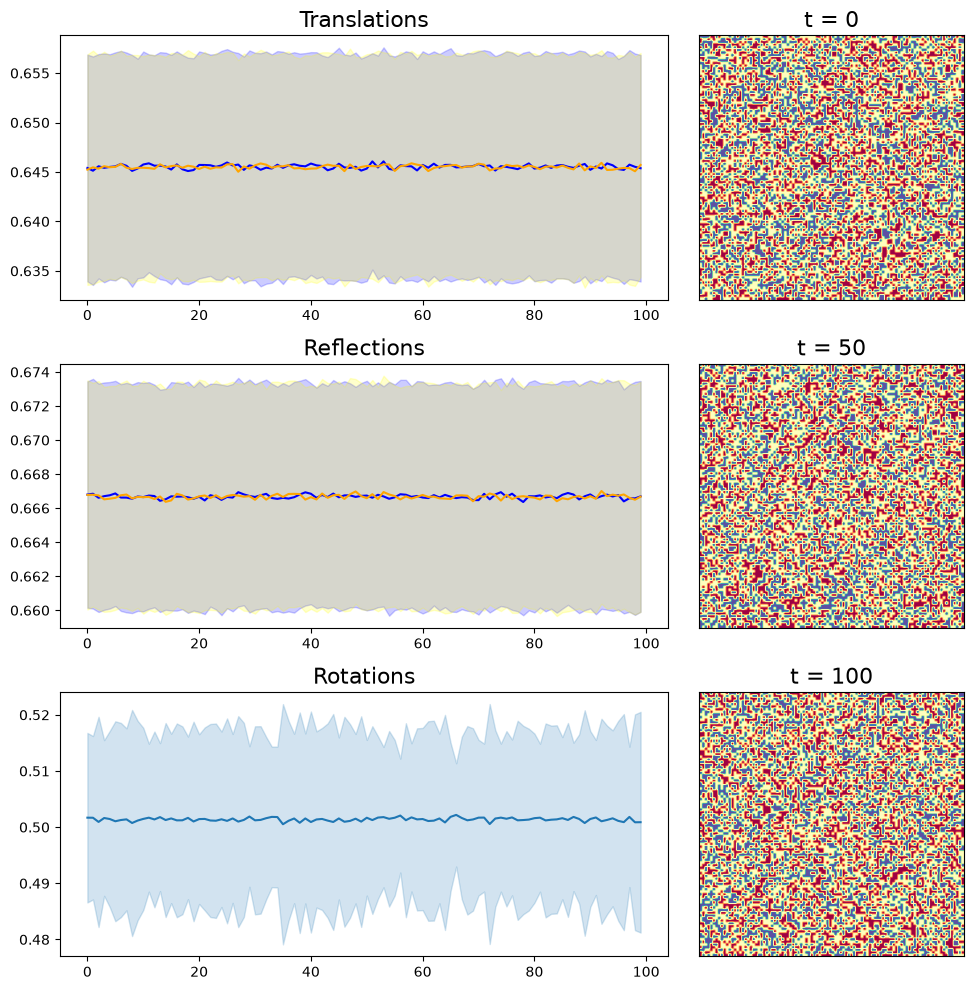

In [2]:
fig = plt.figure(figsize=(10, 10))
layout = fig.add_gridspec(3, 3)

# Each entry specifies the archive row, line colour, and band colour.
panels = (
    ("Translations", ((0, "blue", "blue"), (1, "orange", "yellow"))),
    ("Reflections", ((2, "blue", "blue"), (3, "orange", "yellow"))),
    ("Rotations", ((4, "tab:blue", "tab:blue"),)),
)

for row, (title, series) in enumerate(panels):
    ax = fig.add_subplot(layout[row, :2])
    ax.set_title(title, fontsize=16)

    for index, line_colour, band_colour in series:
        ax.plot(time, mean[index], color=line_colour)
        ax.fill_between(
            time,
            mean[index] - std[index],
            mean[index] + std[index],
            color=band_colour,
            alpha=0.2,
        )

    step = snapshot_steps[row]
    ax_snapshot = fig.add_subplot(layout[row, 2])
    ax_snapshot.imshow(
        snapshots[step],
        cmap="Spectral",
        vmin=0,
        vmax=2,
        interpolation="hanning",
        interpolation_stage="data",
    )
    ax_snapshot.set_title(f"t = {step}", fontsize=16)
    ax_snapshot.set_xticks([])
    ax_snapshot.set_yticks([])

fig.tight_layout()
plt.show()